# Metamodel validation (propagation holdout)

Three steps:

1. **Fit** — `mm.fit(goal)` or `mm.fit_all()`
2. **Validate** — `val.sweep(goal)` for metrics; `val.validate(goal, n=…)` for plotting
3. **Plot** — `result.plot('10m')`, `result.plot_all()`, …

Validation loads saved models only (no refitting). Metrics are reported per isobath depth, mesh polygon, and buoy.

In [1]:
import matplotlib.pyplot as plt
from utils import metamodel as mm
from utils import validation as val
from utils.config import METAMODEL, load_goals, mda_max_points

In [2]:
goals = list(load_goals().keys())
candidates = METAMODEL["mda_candidates"]

print(f"goals      : {goals}")
print(f"candidates : {candidates}")
print(f"MDA max    : {mda_max_points()} (test cases = 500 - max)")
print(f"Hs filter  : > {METAMODEL['site_filter']['hs_max']} m removed before PCA")
print(f"Tp filter  : < {METAMODEL['site_filter']['tp_min']} s removed before PCA")

goals      : ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11']
candidates : [25, 75, 125, 200, 300, 450]
MDA max    : 450 (test cases = 500 - max)
Hs filter  : > 10.0 m removed before PCA
Tp filter  : < 0.5 s removed before PCA


## 1. Fit

In [ ]:
# All goals:
mm.fit_all(gp_epochs=1500)

2026-06-30 11:16:41,799 - Samoa.metamodel - INFO - Goal 1: loaded MDA (450 train, 50 test)
2026-06-30 11:16:41,801 - Samoa.metamodel - INFO - Goal 1 / n=25: loaded models
2026-06-30 11:16:42,254 - Samoa.metamodel - INFO - Goal 1 / n=75: loaded models
2026-06-30 11:16:42,716 - Samoa.metamodel - INFO - Goal 1 / n=125: loaded models
2026-06-30 11:16:43,130 - Samoa.metamodel - INFO - Goal 1 / n=200: loaded models
2026-06-30 11:16:43,595 - Samoa.metamodel - INFO - Goal 1 / n=300: loaded models
2026-06-30 11:16:44,154 - Samoa.metamodel - INFO - Goal 1 / n=450: loaded models
2026-06-30 11:16:44,944 - Samoa.metamodel - INFO - Goal 2: loaded MDA (450 train, 50 test)
2026-06-30 11:16:44,944 - Samoa.metamodel - INFO - Goal 2 / n=25: loaded models
INFO:PCA:Setting self.num_workers to 1. Change it using self.set_num_processors_to_use method.
INFO:PCA:
        -------------------------------------------------------------------
        | Initializing PCA reduction model with the following parameters:

## 2. Validate

In [4]:
# Metrics for every MDA size → outputs/goal_01/validation_metrics.csv
metrics = val.sweep("1")
metrics.head()

2026-06-30 11:04:57,371 - Samoa.validation - INFO - Goal 1: validating n=25


INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed max custom scaler for spr is lower than datapoint
INFO:ExactGPInterpolation:Proposed min custom scaler for wl is bigger than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for wl is lower than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for dir_u is lower than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInterpolation:Predicting target variable: hs__PC4
INFO:ExactGPInterpolation:Predicting target variable: hs__PC5
INFO:ExactGPInterpolation:Predicting target variable: hs__PC6

,goal,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2
0,1,25,50,"{'hs': 0.99, 'dir': 0.99}",5m,isobath,5m,hs,Hs,4100,-1.185676e-02,8.380790e-02,0.747800
1,1,25,50,"{'hs': 0.99, 'dir': 0.99}",5m,isobath,5m,tp,Tp,4100,1.241373e-08,8.333811e-07,1.000000
2,1,25,50,"{'hs': 0.99, 'dir': 0.99}",5m,isobath,5m,dir,Dir,4100,-3.838603e+00,1.887375e+01,0.902519
3,1,25,50,"{'hs': 0.99, 'dir': 0.99}",10m,isobath,10m,hs,Hs,5000,-7.284697e-03,7.701026e-02,0.750502
4,1,25,50,"{'hs': 0.99, 'dir': 0.99}",10m,isobath,10m,tp,Tp,5000,1.147401e-08,8.223212e-07,1.000000


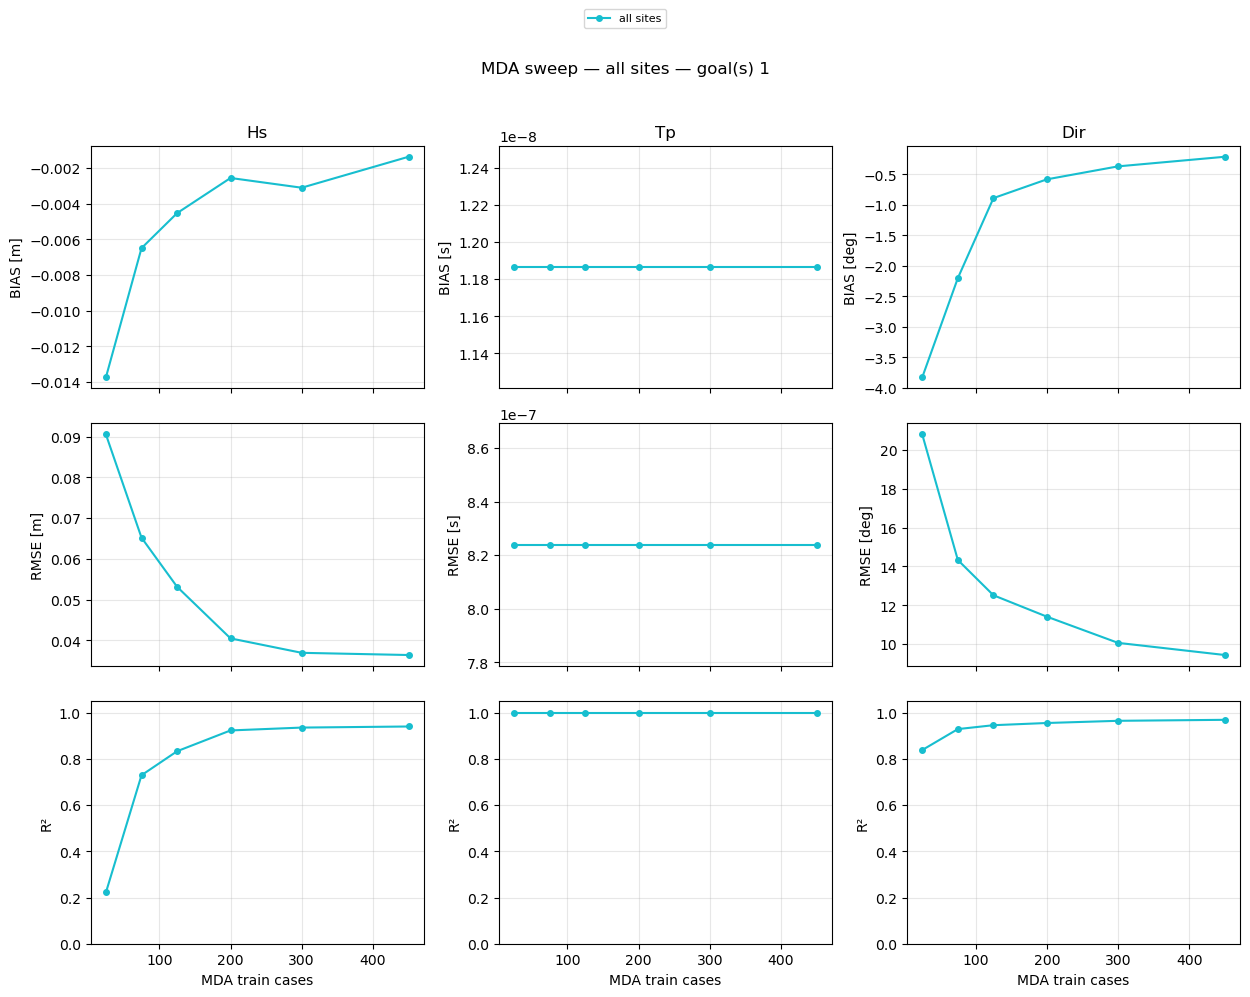

In [5]:
val.plot_sweep(metrics, by="bulk")
plt.show()

## 3. Plot

In [6]:
n = 450  # MDA size to plot
result = val.validate(1, n)

# Available groups: isobath depths, mesh labels, buoy ids
[g[0] for g in val.metric_groups(result.estimate)]

INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInterpolation:Predicting target variable: hs__PC4
INFO:ExactGPInterpolation:Predicting target variable: hs__PC5
INFO:ExactGPInterpolation:Predicting target variable: hs__PC6
INFO:ExactGPInterpolation:Predicting target variable: hs__PC7
INFO:ExactGPInterpolation:Predicting target variable: hs__PC8
INFO:ExactGPInterpolation:Predicting target variable: hs__PC9
INFO:ExactGPInterpolation:Predicting target variable: hs__PC10
INFO:ExactGPInterpolation:Predicting target variable: hs__PC11
INFO:ExactGPInterpolation:Pr

['5m',
 '10m',
 '20m',
 '50m',
 'Apia',
 'buoy_Apolima_Buoy',
 'buoy_Apolima_Javi_Buoy',
 'buoy_American_Samoa_Buoy',
 'buoy_Aunuu_Buoy']

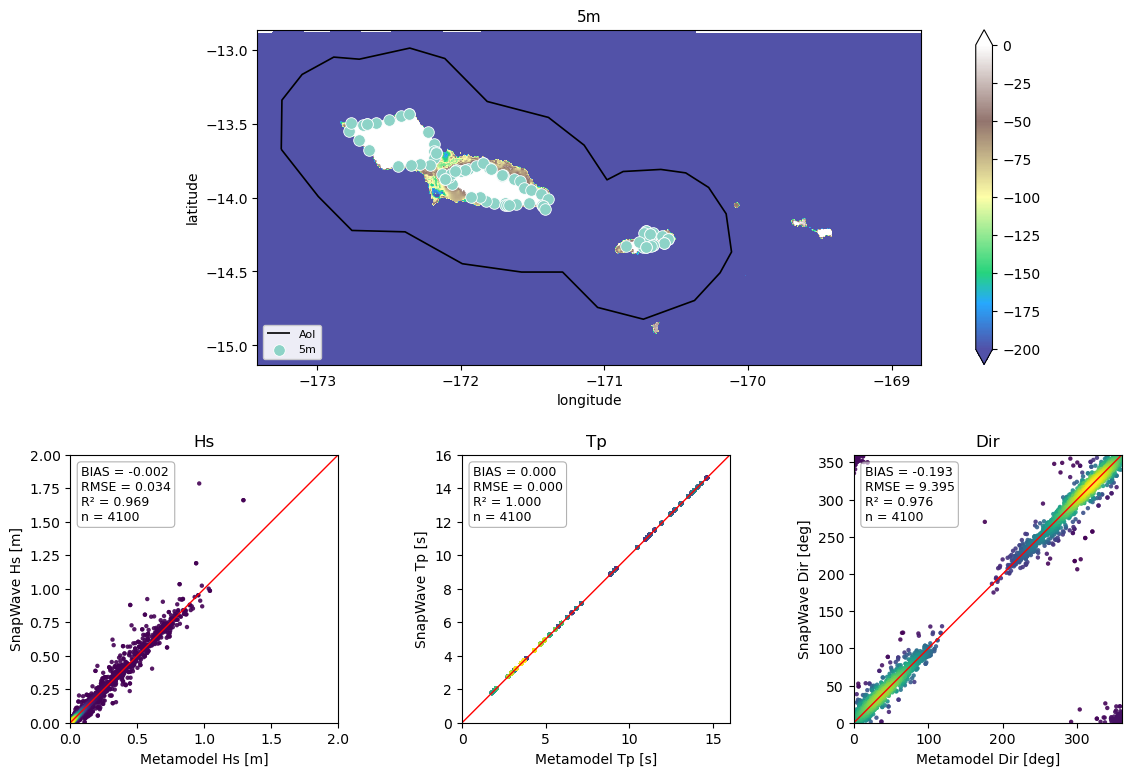

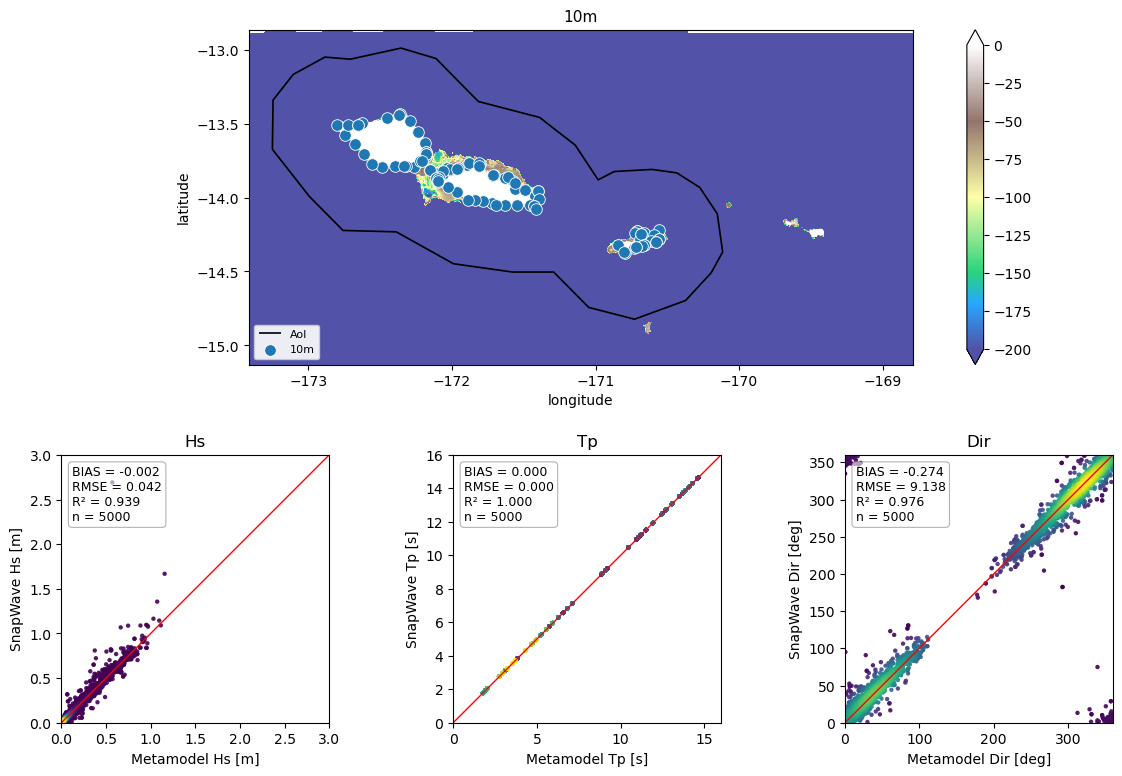

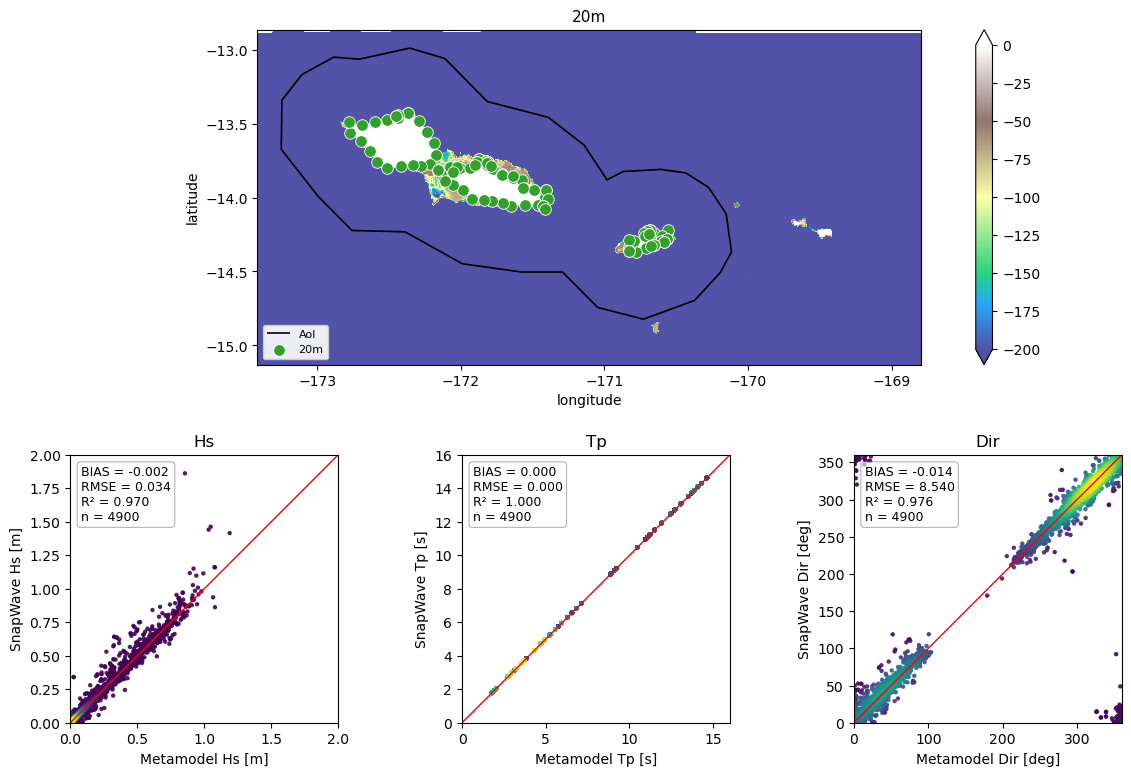

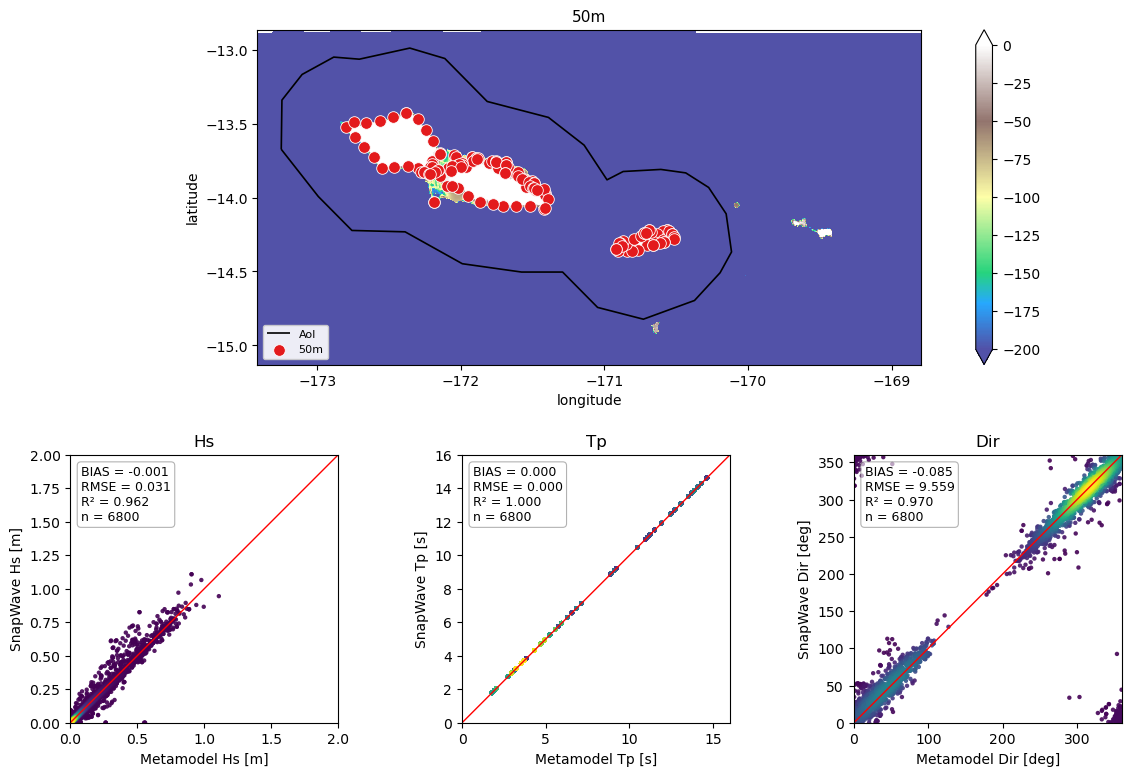

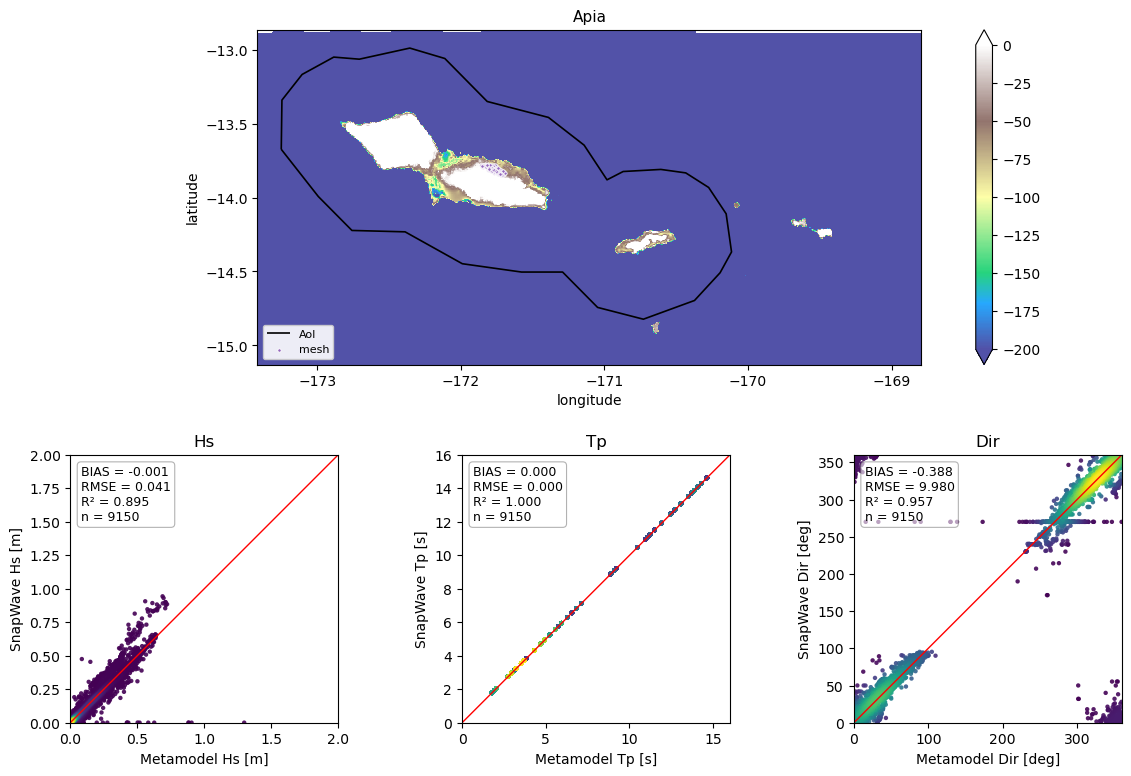

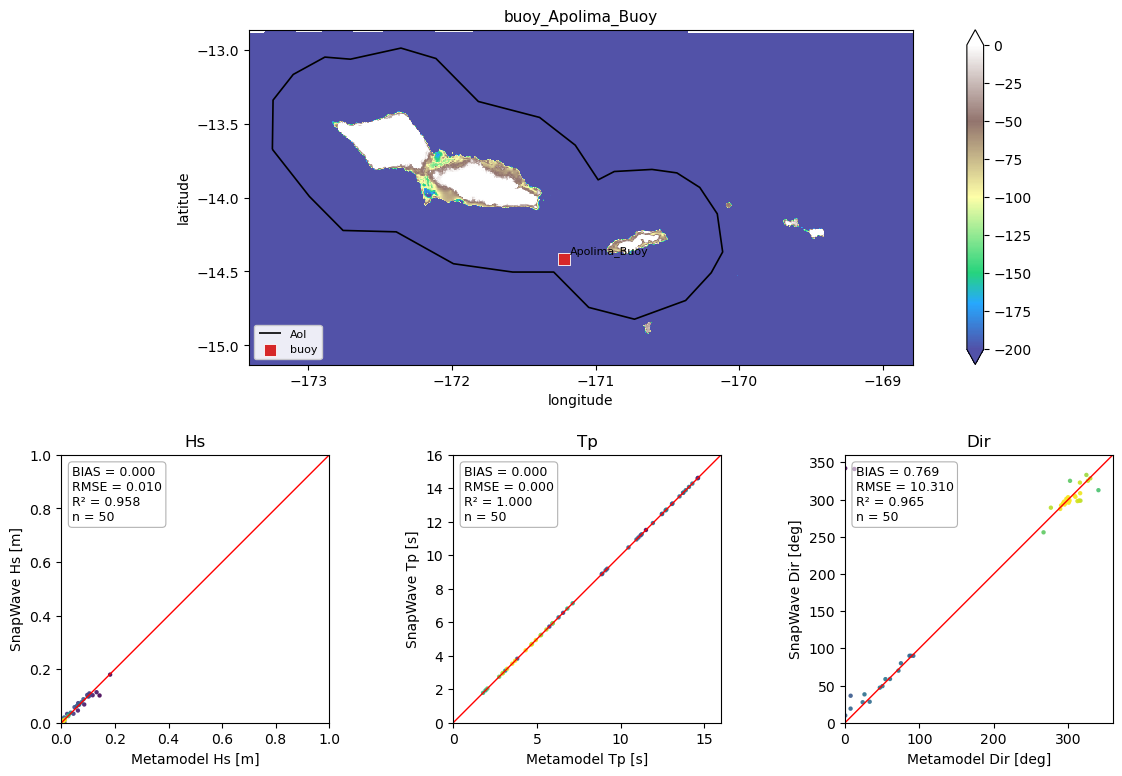

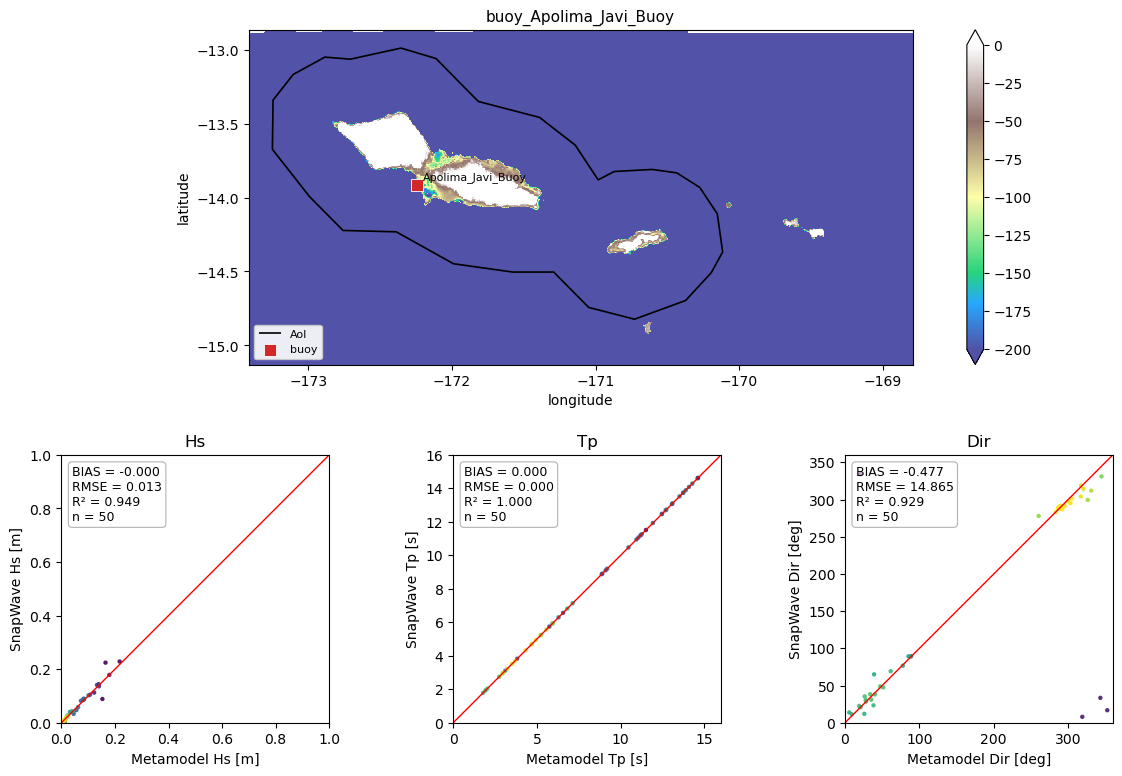

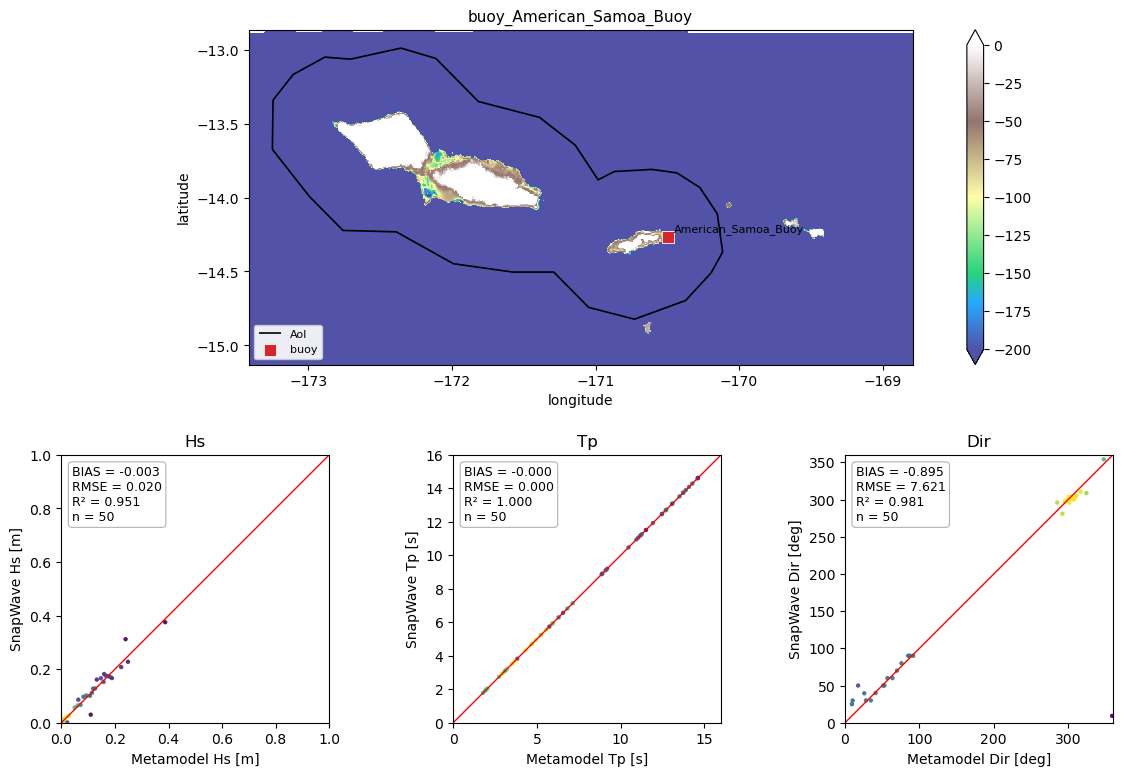

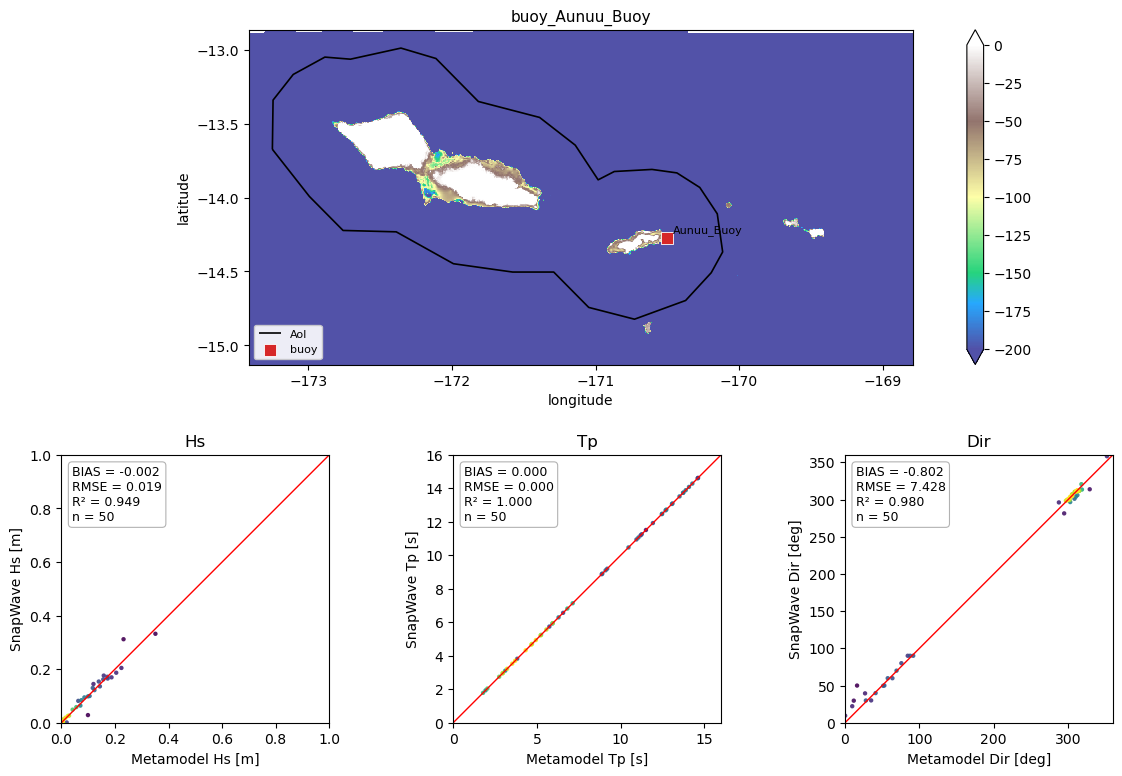

In [7]:
# Map only, or scatters only
# result.plot_map("10m")
# result.plot_scatter("10m", variables=["hs"])

# All groups (optionally filter variables or groups)
for fig in result.plot_all(variables=["hs", "tp", "dir"]):
    plt.show()

## All goals

In [ ]:
all_metrics = val.sweep_all()
all_metrics

In [ ]:
# Best MDA size per goal (10m isobath, Hs)
hs_10m = all_metrics.query("site_label == '10m' and variable == 'hs'")
best = hs_10m.loc[hs_10m.groupby("goal")["rmse"].idxmin()]
best[["goal", "mda_candidate", "site_label", "rmse", "r2", "n"]]